# Практикум 1, часть 1. Вопрос редактора: от ответа модели к ответу агента

Курс «От интеллектуального поиска к интеллектуальным агентам», ВМК МГУ.

**Что мы делаем и зачем.** В курсе строится ассистент, который отвечает на вопросы по предметной области и у каждого утверждения показывает источник и проверку. Языковая модель в нём одна из частей. Этот блокнот собирает такого ассистента на маленьком примере и по ходу показывает, какую ошибку модели снимает каждая часть: корпус с поиском, граф связей, правила над данными, внешняя проверка.

Один вопрос проходит через весь блокнот:

> **Какие статьи можно выносить на решение редколлегии, и на что опирается это требование?**

Пример один на всех: редактор сборника решает, какие статьи выносить на редколлегию. У него 8 статей, журнал на 14 рецензий и положение о статьях из 31 записи.

| Пример | Что делаем | Вопрос до запуска |
|---|---|---|
| 0 | спрашиваем модель без инструментов | сколько статей из восьми она разрешит вынести? |
| 1 | поиск по словам и путь по графу | что вернёт поиск на вопрос «на что опирается 6.5»? |
| 2 | правила над журналом | какая средняя оценка у статьи P2: 6,5 или 8,5? |
| 3 | агент собирает ответ сам | какой инструмент модель вызовет первым? |

Правило работы: **сначала прогноз, потом запуск**.

In [1]:
import sys; sys.path.insert(0, "agent")   # ядро агента, инструменты и выбор модели лежат в agent/
import json, os, pandas as pd
from llm_local import pick_llm, ask_plain_or_record, run_live_or_record
import agent_l1 as a            # инструменты и инструкция агента лекции 1
import viz

pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 170)
LLM, note = pick_llm()
print("модель:", note)
if LLM: print("ответ модели может занимать до минуты на процессоре; предел ожидания задаёт LLM_TIMEOUT")

модель: локальная модель qwen-agent через Ollama
ответ модели может занимать до минуты на процессоре; предел ожидания задаёт LLM_TIMEOUT


## Данные

Журнал рецензий: 14 строк. Его редактор держит в руках.

In [2]:
a.reviews

,статья,авторы_организация,рецензент,рецензент_организация,назначено,сдано,оценка,шкала,ответ_авторов
0,P1,МГУ,Rv1,ФИЦ ИУ,2026-09-01,2026-09-15,8,10,да
1,P1,МГУ,Rv2,МФТИ,2026-09-01,2026-09-18,7,10,да
2,P2,МФТИ,Rv3,ИТМО,2026-09-01,2026-09-12,4,5,да
3,P2,МФТИ,Rv1,ФИЦ ИУ,2026-09-01,2026-09-20,9,10,да
4,P3,ФИЦ ИУ,Rv4,ФИЦ ИУ,2026-09-02,2026-09-16,9,10,да
5,P3,ФИЦ ИУ,Rv2,МФТИ,2026-09-02,2026-09-19,6,10,да
6,P4,ИТМО,Rv5,МГУ,2026-09-02,2026-09-14,8,10,да
7,P5,МГУ,Rv3,ИТМО,2026-09-03,2026-09-30,7,10,да
8,P5,МГУ,Rv6,МФТИ,2026-09-03,2026-09-17,6,10,да
9,P6,МФТИ,Rv4,ФИЦ ИУ,2026-09-03,2026-09-15,3,10,нет


## Пример 1. Модель без инструментов

Модель получает вопрос и журнал текстом. Столбец «шкала» в текст не попадает: так обычно и бывает, когда таблицу копируют в чат.

**Прогноз.** Сколько статей из восьми модель разрешит вынести на решение? Запишите число.

In [3]:
QUESTION = a.QUESTION
RECORD_PLAIN = '''[запись характерного ответа модели без инструментов]
Все восемь статей можно выносить на решение редколлегии. Средние оценки: P1 — 7,5; P2 — 6,5; P3 — 7,5;
P4 — 8; P5 — 6,5; P6 — 4; P7 — 8,5; P8 — рецензия ожидается, статья может быть рассмотрена по имеющимся данным.
Требование о принятии решения опирается на п. 6.1 (две рецензии) и п. 6.4 (ответ авторов), а также на
ГОСТ Р 7.0.113-2021 «Рецензирование научных статей. Общие требования», п. 5.4.
По статье P2: замечание рецензента Rv3 к утверждению 3 необоснованно, доказательство утверждения 3 корректно.'''

journal = "Журнал рецензий:\n" + a.reviews.drop(columns=["шкала"]).to_csv(index=False)
ANSWER_PLAIN = ask_plain_or_record(LLM, QUESTION, journal, RECORD_PLAIN)

Для принятия решения редколлегии по данным журнала рецензий вы можете учитывать несколько факторов. Вот различные статьи и соответствующие положения:

### Статьи для выноса на решение редколлегии:
1. **Статусы рецензентов**:
   - Продолжительность процесса рецензирования: сравнивать сроки сдачи рецензий и времени, требуемого для принятия решения.
   
2. **Качество оценок**:
   - Оценки рецензий (например, оценка 9 или выше может быть признана качественной).

3. **Репутация авторов/организаций**:
   - Авторы и организации с плохой репутацией могут подлежать дополнительной проверке.

4. **Качество ответов авторов (при наличии)**:
   - Рекомендации, которые принять или игнорировать в будущем.

5. **Согласованность оценки и рецензии**:
   - Если рецензенты имеют различную оценку, можно рассмотреть совокупный анализ мнений для принятия окончательного решения.

### Положения основанные на документах:

1. **Положение журнала (например, "Положение о научном журнале" или "Регламент проведения р

### Игра «найди ошибки»

Прочитайте ответ и найдите в нём то, чему нельзя верить. В записи характерного ответа ошибок четыре.

| Что сказано | В чём дело | Чего не хватило модели |
|---|---|---|
| средняя оценка P2 равна 6,5 | усреднены 4 из 5 и 9 из 10 | **схемы данных**: у числа нет шкалы |
| ГОСТ Р 7.0.113-2021 | такого документа нет | **источника**: ответ имеет вид правильного |
| все восемь можно выносить | требования 6.1, 6.2, 6.5, 6.6 не проверены | **правил** и механизма их применения |
| доказательство утверждения 3 корректно | утверждение ложно | **внешней проверки** доказательства |

Пункты 6.1 и 6.4 названы верно: они есть в положении. По тексту ответа верное от выдуманного отличить нельзя.

Живая модель ответит иначе. Проверяйте её ответ по тем же четырём строкам.

## Пример 2. Слова и граф

Вторая половина вопроса: на что опирается требование 6.5. Спросим поиск по словам.

**Прогноз.** Что вернёт поиск: (а) цепочку положений, на которые опирается 6.5, (б) сам пункт 6.5 и похожие по словам, (в) ничего?

In [4]:
QUERY = "на какие положения опирается требование 6.5 о принятии решения редколлегией"
pd.DataFrame(a.search_words(QUERY))

,id,название,bm25
0,R65,6.5 Принятие решения,6.02
1,R53,5.3 Ключевые слова,3.01
2,R64,6.4 Ответ на замечания,2.81
3,R51,5.1 Объём статьи,2.73
4,R52,5.2 Аннотация,2.65


Поиск нашёл сам пункт 6.5 и положения с похожими словами. Цепочки нет: в тексте пункта 6.5 нет слов «раздел 3» или «термин Рецензент». Ответ на вопрос о зависимости записан в связях между документами.

Теперь тот же вопрос графу. Столбец `зависит_от` корпуса становится рёбрами.

In [5]:
deps = a.graph_deps("R65")
print(len(deps["опирается_на"]), "положений:")
for x in deps["опирается_на"]:
    print("  ", x)

14 положений:
   R61 6.1 Число рецензий
   R63 6.3 Содержание рецензии
   R64 6.4 Ответ на замечания
   S01 Раздел 1. Область применения
   S03 Раздел 3. Термины и определения
   S06 Раздел 6. Порядок рецензирования
   T01 Статья
   T04 Автор
   T05 Рецензент
   T06 Рецензия
   T07 Замечание
   T08 Ответ авторов
   T09 Редакционная коллегия
   T10 Решение


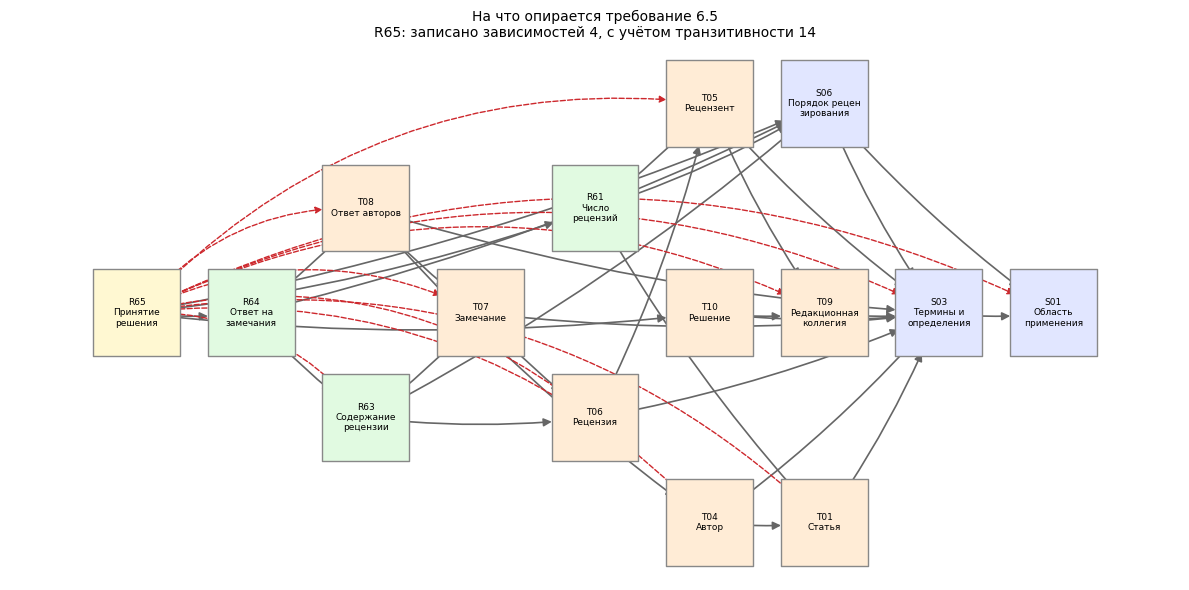

сплошные стрелки записаны в корпусе, пунктирные получены проходом по цепочкам: 10


In [6]:
n = viz.draw_deps(a.corpus, "R65", show_inferred=True, title="На что опирается требование 6.5")
print("сплошные стрелки записаны в корпусе, пунктирные получены проходом по цепочкам:", n)

**Что увидели.** В корпусе у пункта 6.5 записаны 4 зависимости. Проход по цепочкам даёт 14. Каждый шаг цепочки записан в корпусе с источником.

**В задании 1** это ваши `kg/corpus.csv` (столбец `зависит_от`) и вопрос типа «зависимость».

## Пример 3. Правило и данные

Первая половина вопроса: какие статьи можно выносить. Посмотрим на статью P2.

**Прогноз.** Какая у P2 средняя оценка: 6,5 или 8,5?

In [7]:
a.reviews[a.reviews["статья"] == "P2"][["статья", "рецензент", "оценка", "шкала"]]

,статья,рецензент,оценка,шкала
2,P2,Rv3,4,5
3,P2,Rv1,9,10


In [8]:
verdict = pd.DataFrame(a.check_rules())
verdict

,статья,выносить,средняя оценка (шкала 10),причина
0,P1,да,7.5,—
1,P2,да,8.5,—
2,P3,нет,7.5,6.2 (рецензент не из организации авторов)
3,P4,нет,8.0,"6.1 (не менее двух сданных рецензий), 6.5 (есть ответ авторов на замечания)"
4,P5,нет,6.5,6.6 (рецензии сданы в 21 день)
5,P6,нет,4.0,6.5 (есть ответ авторов на замечания)
6,P7,да,8.5,—
7,P8,нет,NaN,"6.1 (не менее двух сданных рецензий), 6.5 (есть ответ авторов на замечания)"


**Что увидели.** Оценка 4 выставлена по шкале 5, это 8 из 10. Средняя оценка P2 равна 8,5. Готовы к решению три статьи: P1, P2, P7. У каждой из остальных названо нарушенное требование.

Проверка состоит из трёх частей: правило из положения, данные со схемой, код, который применяет правило к данным. Правила лежат в словаре `RULES`:

In [9]:
for k, (text, _) in a.RULES.items():
    print(k, "—", text)

6.1 — не менее двух сданных рецензий
6.2 — рецензент не из организации авторов
6.6 — рецензии сданы в 21 день
6.5 — есть ответ авторов на замечания


## Пример 4. Агент собирает ответ сам

Примеры 2 и 3 запускали мы. Теперь инструменты получает модель. Агент есть цикл: модель пишет вызов инструмента, программа его исполняет, результат возвращается модели, и так до ответа без вызовов.

Что модель получает: инструкцию и описания четырёх инструментов.

In [10]:
print("ИНСТРУКЦИЯ\n" + a.SYSTEM + "\n\nИНСТРУМЕНТЫ")
for t in a.TOOLS:
    f = t["function"]
    print(f"  {f['name']:18} {f['description']}")

ИНСТРУКЦИЯ
Ты ассистент редактора сборника. Отвечай по-русски. Сначала вызови инструменты, затем отвечай только по их результатам. Каждую часть ответа помечай: [проверено: инструмент] или [найдено: инструмент]. Документы и пункты, которых нет в результатах инструментов, не называй. Если после вызова инструментов что-то не подтвердилось, помечай это [не подтверждено]. Идентификатор требования 6.5 в корпусе: R65.

ИНСТРУМЕНТЫ
  search_words       Поиск по словам (BM25) по корпусу положения.
  graph_deps         На какие положения транзитивно опирается документ (граф знаний, зависит_от+).
  check_rules        Применить правила 6.1, 6.2, 6.5, 6.6 положения к журналу рецензий. Вердикт по каждой статье.
  lean_check_claims  Вердикты внешнего верификатора доказательств по утверждениям статьи P2.


**Прогноз.** Какой инструмент модель вызовет первым? Сколько всего вызовов она сделает?

In [11]:
messages = run_live_or_record(LLM, QUESTION, a.SYSTEM, a.TOOLS, a.IMPL, a.PLAN, a.RECORD)

[1] модель вызвала check_rules({})
    <- [{"статья": "P1", "выносить": "да", "средняя оценка (шкала 10)": 7.5, "причина": "—"}, {"статья": "P2", "выносить": "да", "средняя оценка (шкала 10)": 8.5, "при…
[2] модель вызвала check_rules({})
    <- [{"статья": "P1", "выносить": "да", "средняя оценка (шкала 10)": 7.5, "причина": "—"}, {"статья": "P2", "выносить": "да", "средняя оценка (шкала 10)": 8.5, "при…
[3] ответ модели:
orning,

Статьи, которые можно выносить на решение редколлегии по данным журнала рецензий:

- **P1**
- **P2**
- **P7**

Эти статьи опираются на требования **6.5** (есть ответ авторов на замечания).

[время: 17.6 с]


### Как читать протокол

- Строка «модель вызвала» есть запрос модели: имя инструмента и аргументы.
- Строка со стрелкой есть результат, который вернула программа.
- Последняя запись есть ответ.

**Как проверять ответ.** Каждое утверждение ответа нужно найти в результатах инструментов. Пометки в квадратных скобках подсказывают, где искать. Если утверждения в результатах нет, оно порождено моделью и не проверено.

Ниже тот же прогон изнутри: список сообщений, который модель получает целиком при каждом обращении.

In [12]:
for i, m in enumerate(messages):
    kind = m["role"] + (" → вызов " + m["tool_calls"][0]["function"]["name"] if m.get("tool_calls") else "")
    print(f"{i:2} {kind:38} {str(m.get('content') or '')[:70]}")

 0 system                                 Ты ассистент редактора сборника. Отвечай по-русски. Сначала вызови инс
 1 user                                   Какие статьи можно выносить на решение редколлегии по данным журнала р
 2 assistant → вызов check_rules          
 3 tool                                   [{"статья": "P1", "выносить": "да", "средняя оценка (шкала 10)": 7.5, 
 4 assistant → вызов check_rules          
 5 tool                                   [{"статья": "P1", "выносить": "да", "средняя оценка (шкала 10)": 7.5, 
 6 assistant                              orning,

Статьи, которые можно выносить на решение редколлегии по данн


## До и после

| | Модель без инструментов | Агент с инструментами |
|---|---|---|
| какие статьи выносить | все восемь | P1, P2, P7, у остальных названо требование |
| средняя оценка P2 | 6,5 | 8,5 |
| на что опирается 6.5 | два верных пункта и выдуманный документ | 14 положений из корпуса |
| утверждение 3 статьи P2 | «корректно» | отклонено внешней проверкой |
| откуда каждое утверждение | неизвестно | пометка и строка протокола |

Модель осталась той же. Изменилось то, что находится вокруг неё: схема данных, граф, правила, внешняя проверка.

## Что повторить самостоятельно

1. Запустить этот блокнот. Найти ошибки в ответе модели без инструментов.
2. Задать поиску и графу свой вопрос о зависимости по корпусу положения.
3. Перейти к блокноту `practice_3_tasks.ipynb`: там оба задания выполнены на маленькой области.